# dSprite V3

Causal MSE, mean over 10 data seeds (3 repeats averaged within each seed). DRPCLNET rows: `kkt-mean` arm. Kernel rows: Nyström KPV, KAP, DRKPV.

In [1]:
import sys, os, glob
sys.path.insert(0, "../../src")
import numpy as np
import pandas as pd
from python_utils.visualization_utils import plot_pcl_convergence_ci

COLS = ["Algorithm", "Data_Seed", "Repeat", "Causal_MSE"]

def load(pattern, label, tag=None, arm=None, sweep=False, diverge_above=None):
    """One method family -> tidy frame. Files are read oldest-first so that, when a preempted task
    left a partial CSV next to its complete rerun, the NEWEST row wins on each key."""
    cols = COLS + (["n_sample"] if sweep else [])
    files = sorted(glob.glob(pattern), key=os.path.getmtime)
    frames = [d for d in map(pd.read_csv, files) if len(d) and "Algorithm" in d.columns]
    if not frames:
        print("%-12s no rows" % label); return pd.DataFrame(columns=cols)
    d = pd.concat(frames, ignore_index=True)
    if arm is not None and "normalization" in d.columns:
        d = d[d.normalization == arm]
    if tag is not None and "tag" in d.columns:
        d = d[d.tag == tag]
    d["Causal_MSE"] = pd.to_numeric(d["Causal_MSE"], errors="coerce")
    d = d.dropna(subset=["Causal_MSE"])
    if diverge_above is not None:
        for a in sorted(set(d.Algorithm[d.Causal_MSE > diverge_above])):
            print("%-12s %s diverged on %d/%d runs -- not shown"
                  % (label, a, int(((d.Algorithm == a) & (d.Causal_MSE > diverge_above)).sum()),
                     int((d.Algorithm == a).sum())))
        d = d[d.Causal_MSE <= diverge_above]
    key = [c for c in cols if c != "Causal_MSE"] + (["Anchor"] if "Anchor" in d.columns else [])
    d = d.drop_duplicates(key, keep="last")
    return d[cols + (["Anchor"] if "Anchor" in d.columns else [])]

def per_seed(frames, full_seeds=10, sweep=False):
    """Mean over repeats (and anchors) within a data seed; a cell short of the full seed grid is dropped."""
    d = pd.concat([f for f in frames if len(f)], ignore_index=True)
    grp = ["Algorithm"] + (["n_sample"] if sweep else [])
    ps = d.groupby(grp + ["Data_Seed"]).Causal_MSE.mean()
    cov = ps.groupby(grp).size()
    short = set(cov[cov < full_seeds].index)
    if short:
        print("incomplete (dropped): " + ", ".join(map(str, sorted(short, key=str))))
        keep = [tuple(k[:len(grp)]) if sweep else k[0] for k in ps.index]
        ps = ps[[k not in short for k in keep]]
    return ps

# paper names (tables and, after the legend relabel in save, figures)
NAMES = {"OutcomeNet": "OutcomeNet", "TreatmentNet": "TreatmentNet",
         "DRPCLNET-V1": "DR-PCL-Net", "DRPCLNET": "DR-PCL-Net",
         "KPV": "KPV", "KAP": "KAP", "DRKPV": "DRKPV",
         "KPV_Nystrom": "KPV (Nystrom)", "KAP_Nystrom": "KAP (Nystrom)", "DRKPV_Nystrom": "DRKPV (Nystrom)",
         "PKDR-h": "PKDR-h", "PKDR-q": "PKDR-q", "PKDR": "PKDR", "NMMR-U": "NMMR-U", "NMMR-V": "NMMR-V",
         "DR self-norm": "DR-PCL-Net"}

def table(ps, order, sweep=False, scale=1.0, nd=4):
    """MSE as 'mean ± SE' -- SE over data seeds (repeats already averaged within each seed)."""
    have = [a for a in order if a in ps.index.get_level_values("Algorithm")]
    grp = ["Algorithm"] + (["n_sample"] if sweep else [])
    g = ps.groupby(grp)
    m, se = g.mean() * scale, g.std() / np.sqrt(g.size()) * scale
    cell = m.map(lambda x: "%.*f" % (nd, x)) + " ± " + se.map(lambda x: "%.*f" % (nd, x))
    if sweep:
        t = cell.unstack("n_sample").reindex(have)
        t.columns = ["n=%d" % c for c in t.columns]
    else:
        t = cell.reindex(have).to_frame("MSE ± SE")
    t.index = [NAMES[a] for a in t.index]
    print(t.to_string(na_rep="-"))
    return t

# the plot helper keys its palette/legend on these paper names (unknown names are silently dropped)
# the plot helper keys its palette/legend on the names registered in visualization_utils, and SILENTLY
# DROPS unknown ones -- so series are plotted under those keys and the legend text is fixed up in save
PLOT_NAMES = dict(NAMES, **{"OutcomeNet": "OutcomePCLNet", "TreatmentNet": "TreatmentPCLNet",
                            "DRPCLNET-V1": "DRPCLNET (V1)", "DRPCLNET": "DRPCLNET (V1)",
                            "DR self-norm": "DRPCLNET (V1)"})
LEGEND_RELABEL = {"DRPCLNET (V1)": "DR-PCL-Net", "OutcomePCLNet": "OutcomeNet",
                  "TreatmentPCLNet": "TreatmentNet"}

def save(p, fname):
    """Relabel the legend for the paper, then write Figures/<fname>.pdf (vector) and .png."""
    leg = p.gca().get_legend()
    if leg is not None:                               # palette keys -> the names used in the paper
        for t in leg.get_texts():
            if t.get_text() in LEGEND_RELABEL:
                t.set_text(LEGEND_RELABEL[t.get_text()])
    if fname:
        os.makedirs("Figures", exist_ok=True)
        for ext in ("pdf", "png"):
            p.savefig(os.path.join("Figures", "%s.%s" % (fname, ext)), bbox_inches="tight", dpi=200)

ARM_NAMES = {"none": "none (raw bridge)", "posthoc": "post-hoc", "kkt": "KKT",
             "kkt-mean": "KKT (mean)", "kkt-pca": "KKT (PCA basis)", "phi1": "phi = 1 (control)"}

def ablation(pattern, tag=None, sweep=False, algs=("TreatmentNet", "DRPCLNET-V1"), arms=None,
             scale=1.0, nd=4):
    """Normalization ablation: the SAME runs (same seeds, same shared outcome bridge) under each arm of the
    E[phi|A]=1 enforcement. One table per estimator: rows = arm, columns = sweep sizes (or one MSE column)."""
    files = sorted(glob.glob(pattern), key=os.path.getmtime)
    frames = [d for d in map(pd.read_csv, files) if len(d) and "normalization" in d.columns]
    d = pd.concat(frames, ignore_index=True)
    if tag is not None and "tag" in d.columns:
        d = d[d.tag == tag]
    d["Causal_MSE"] = pd.to_numeric(d["Causal_MSE"], errors="coerce")
    d = d.dropna(subset=["Causal_MSE"])
    keys = [k for k in ["Algorithm", "normalization", "Data_Seed", "Repeat", "n_sample", "Anchor"]
            if k in d.columns]
    d = d.drop_duplicates(keys, keep="last")                     # newest file wins (preempted partials)
    order = arms or [a for a in ARM_NAMES if a in set(d.normalization)]
    grp = ["normalization"] + (["n_sample"] if sweep else [])
    for a in algs:
        x = d[d.Algorithm == a]
        if not len(x):
            continue
        g = x.groupby(grp + ["Data_Seed"]).Causal_MSE.mean().groupby(grp)   # repeats/anchors -> seed -> arm
        cell = (g.mean() * scale).map(lambda v: "%.*f" % (nd, v)) + " ± " + \
               (g.std() / np.sqrt(g.size()) * scale).map(lambda v: "%.*f" % (nd, v))
        t = cell.unstack("n_sample") if sweep else cell.to_frame("MSE ± SE")
        if sweep:
            t.columns = ["n=%d" % c for c in t.columns]
        t = t.reindex([o for o in order if o in t.index])
        t.index = [ARM_NAMES.get(i, i) for i in t.index]
        print(NAMES.get(a, a)); print(t.to_string(na_rep="-")); print()

def plot(ps, order, title, fname=None, also_linear=False):
    """Log-scale figure (the submitted paper's style). also_linear=True writes a second, LINEAR-axis
    copy as <fname>_linear -- same data, same styling, y-axis not log-transformed."""
    if also_linear:
        _plot_one(ps, order, title, fname, log=True)
        return _plot_one(ps, order, title, (fname + "_linear") if fname else None, log=False)
    return _plot_one(ps, order, title, fname, log=True)


def _plot_one(ps, order, title, fname=None, log=True):
    d = ps.reset_index()
    d = d[d.Algorithm.isin(order)].assign(Algorithm=lambda x: x.Algorithm.map(PLOT_NAMES))
    # the submitted paper's style: legend INSIDE the axes, framed with a shadow. <= 5 series: the helper's own
    # default (loc="best", 2 columns). More series: 3 columns at the top, with the log y-axis extended upward
    # just enough to leave an empty band for it, so no data point sits under the legend.
    n = d.Algorithm.nunique()
    kw = dict(legend_kw=dict(loc="upper right", borderaxespad=0.4, borderpad=0.4, labelspacing=0.3,
                             handletextpad=0.5, columnspacing=1.2)) if n <= 5 else \
         dict(legend_kw=dict(loc="upper center", ncol=3, borderaxespad=0.3, borderpad=0.35,
                             labelspacing=0.3, handletextpad=0.5, columnspacing=1.2))
    p = plot_pcl_convergence_ci(d, x_axis_param="n_sample", title=title, **kw)
    ax = p.gca()
    if not log:                                       # the helper always draws a log y-axis
        ax.set_yscale("linear")
        ax.set_ylabel("Causal Mean Squared Error", fontsize=18)
        ax.set_ylim(bottom=0)
    if n > 5:                                         # headroom so no point sits under the legend
        lo, hi = ax.get_ylim()
        band = 0.055 * -(-n // 3) + 0.02             # legend height as a fraction of the axes (tight)
        ax.set_ylim(lo, lo * (hi / lo) ** (1.0 / (1.0 - band)) if log else lo + (hi - lo) / (1.0 - band))
    save(p, fname); p.show()

ours = load("../Results/dSprite_V3_CrossFitting/*.csv", "DRPCLNET", tag="v3lam1", arm="kkt-mean", sweep=True,
            diverge_above=5327)
# NMMR: tuned per arm on tuning seeds 100-102 (batch 64 for V, 512 for U). An arm uses its tuned
# grid only once that grid is COMPLETE (5 sizes x 10 seeds); otherwise it falls back to the published
# grid, so a half-finished relaunch can never silently drop an arm or mix two configurations.
pub = load("../Results/dSprite_V3_NMMR/*.csv", "NMMR pub", tag="v3_sizesweep", sweep=True, diverge_above=5327)
def _complete(f, arm):
    g = f[f.Algorithm == arm]
    cov = g.groupby("n_sample").Data_Seed.nunique()
    return len(cov) == 5 and (cov >= 10).all()
nmmr = []
for arm, tag in [("NMMR-U", "tuned_v3_u"), ("NMMR-V", "tuned_v3_v")]:
    t = load("../Results/dSprite_V3_NMMR/*.csv", tag, tag=tag, sweep=True, diverge_above=5327)
    use_tuned = len(t) and _complete(t, arm)
    print("%-7s -> %s" % (arm, "tuned (%s)" % tag if use_tuned else "published config"))
    nmmr.append((t if use_tuned else pub).pipe(lambda f: f[f.Algorithm == arm]))
kern = load("../Results/dSprite_V3_DRKPV_Nystrom/*.csv", "kernel-Nys", sweep=True, diverge_above=5327)
ps = per_seed([ours] + nmmr + [kern], sweep=True)
ORDER = ["OutcomeNet", "TreatmentNet", "DRPCLNET-V1", "NMMR-U", "NMMR-V",
         "KPV_Nystrom", "KAP_Nystrom", "DRKPV_Nystrom"]

NMMR-U  -> tuned (tuned_v3_u)


NMMR-V  -> tuned (tuned_v3_v)


In [2]:
_ = table(ps, ORDER, sweep=True, nd=3)

                         n=2000          n=5000         n=10000         n=15000         n=20000
OutcomeNet       13.019 ± 0.241  11.666 ± 0.198   9.720 ± 0.214   7.835 ± 0.178   6.942 ± 0.209
TreatmentNet     17.566 ± 0.424  14.935 ± 0.175  14.991 ± 0.147  14.694 ± 0.200  14.413 ± 0.195
DR-PCL-Net       12.527 ± 0.250  11.083 ± 0.210   8.885 ± 0.238   7.116 ± 0.219   5.990 ± 0.167
NMMR-U           34.723 ± 0.252  32.704 ± 0.389  34.721 ± 0.303  31.784 ± 0.325  33.024 ± 0.284
NMMR-V           21.755 ± 1.048  20.110 ± 0.794  19.047 ± 0.559  18.804 ± 0.239  17.685 ± 0.440
KPV (Nystrom)    25.636 ± 0.247  25.544 ± 0.153  25.495 ± 0.119  25.390 ± 0.116  25.498 ± 0.122
KAP (Nystrom)    21.306 ± 0.470  19.576 ± 0.245  19.512 ± 0.150  19.545 ± 0.171  19.287 ± 0.143
DRKPV (Nystrom)  21.734 ± 0.323  20.191 ± 0.219  20.003 ± 0.111  19.956 ± 0.118  19.584 ± 0.088


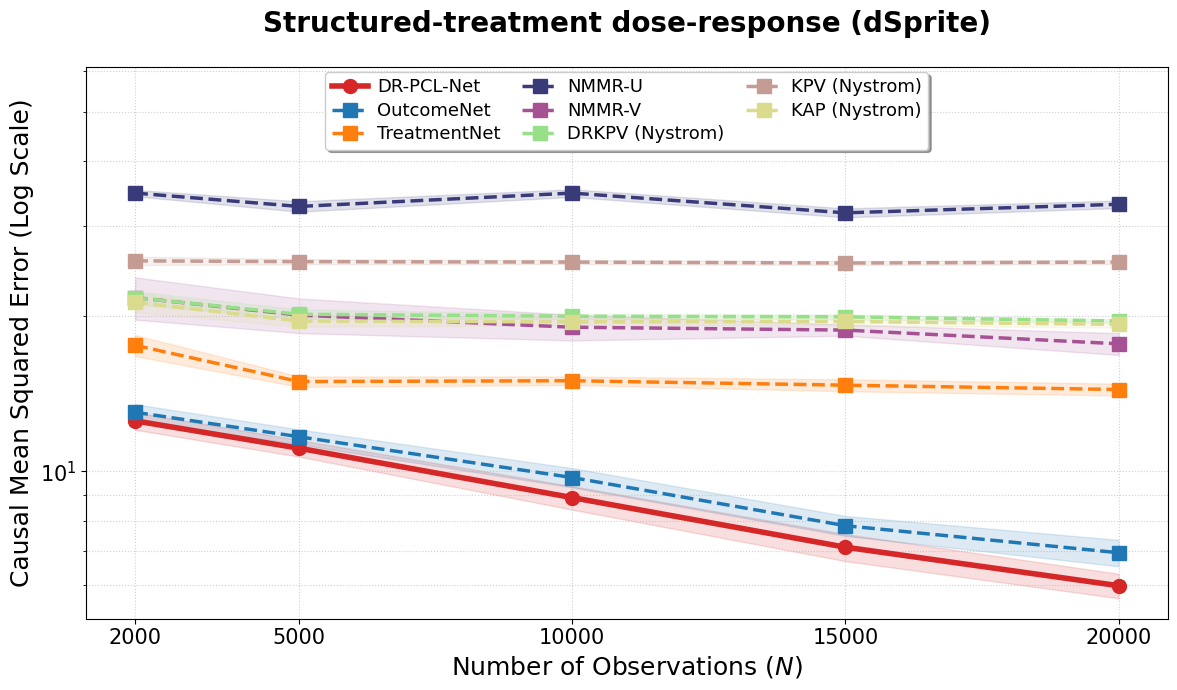

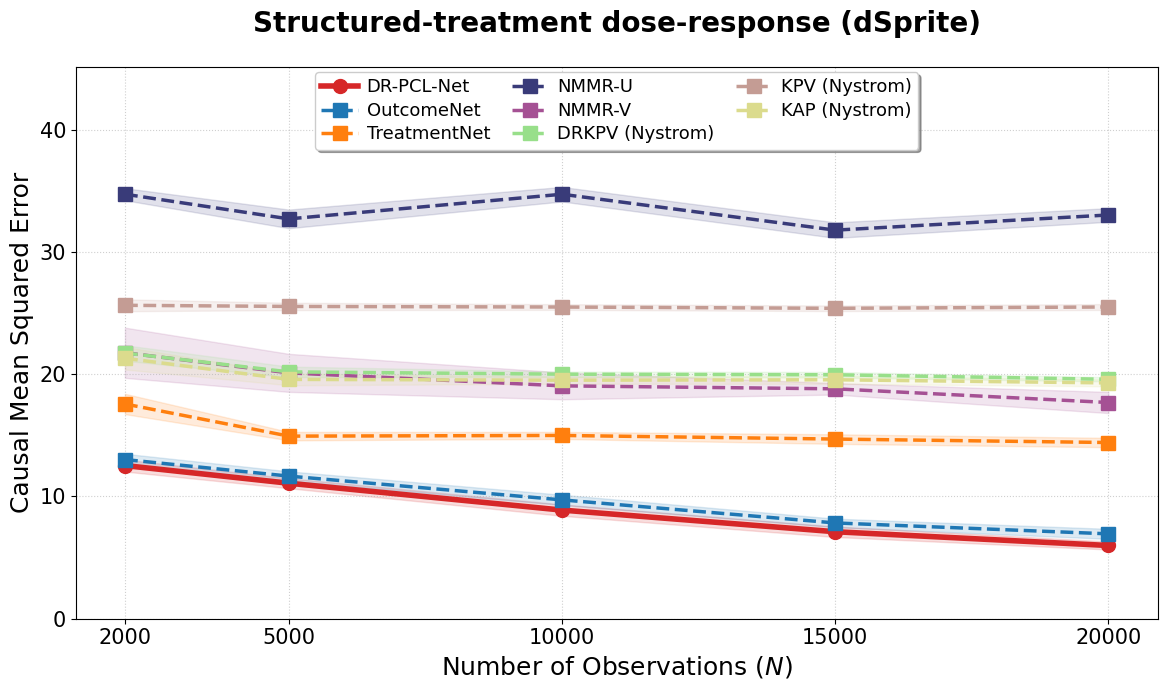

In [3]:
plot(ps, ORDER, "Structured-treatment dose-response (dSprite)", fname="dsprite_v3", also_linear=True)